In [1]:
# The following code will only execute
# successfully when compression is complete

import kagglehub

# Download latest version
path = kagglehub.dataset_download("shaikakram67/deepfake")

print("Path to dataset files:", path)

# Define the directory paths for the training, validation, and test datasets using the correct kagglehub path
train_dir = f'{path}/Dataset/Train'
val_dir   = f'{path}/Dataset/Validation'
test_dir  = f'{path}/Dataset/Test'

Path to dataset files: /kaggle/input/datasets/shaikakram67/deepfake


In [2]:
import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import timm

# Print the installed PyTorch version to verify the environment setup
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ GPU is not enabled. Go to Runtime → Change runtime type → GPU")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Using device: cuda


In [3]:
import os

print("Train exists:", os.path.exists(train_dir))
print("Validation exists:", os.path.exists(val_dir))
print("Test exists:", os.path.exists(test_dir))

# Ensure the directories actually exist before listing them
if os.path.exists(train_dir):
    classes = os.listdir(train_dir)
    num_classes = len(classes)
    print(f'Number of Classes: {num_classes}')
    print("Train folders:", os.listdir(train_dir))
    print("Validation folders:", os.listdir(val_dir))
    print("Test folders:", os.listdir(test_dir))
else:
    print("⚠️ Dataset directories do not exist. Please check dataset path correctness.")

Train exists: True
Validation exists: True
Test exists: True
Number of Classes: 2
Train folders: ['Fake', 'Real']
Validation folders: ['Fake', 'Real']
Test folders: ['Fake', 'Real']


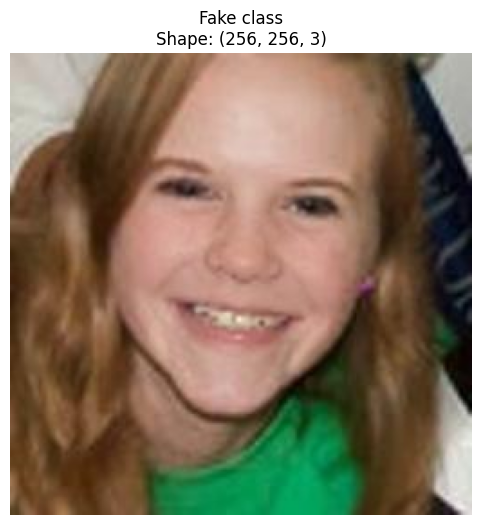

In [4]:
random_class = random.choice(classes)
random_class_path = os.path.join(train_dir, random_class)
image_files = os.listdir(random_class_path)
random_img_name = random.choice(image_files)
random_img_path = os.path.join(random_class_path, random_img_name)

random_img = plt.imread(random_img_path)

plt.figure(figsize=(6, 6))
plt.imshow(random_img)
plt.title(f'{random_class} class\nShape: {random_img.shape}')
plt.axis('off')
plt.show()

In [5]:
# Detect cross-split duplicates and create filtered validation/test copies.
# Run this BEFORE the data pipeline cell. Original dataset folders are left unchanged.
import os, hashlib, csv, shutil
from collections import defaultdict
from pathlib import Path
from PIL import Image
import numpy as np

SPLIT_DIRS = {"train": train_dir, "validation": val_dir, "test": test_dir}
DEDUP_ROOT = "/kaggle/working/dataset_deduplicated"
FILTERED_VAL_DIR = os.path.join(DEDUP_ROOT, "Validation")
FILTERED_TEST_DIR = os.path.join(DEDUP_ROOT, "Test")
DHASH_THRESHOLD = 6
MATCHES_CSV = os.path.join(DEDUP_ROOT, "duplicate_candidates.csv")
SUMMARY_CSV = os.path.join(DEDUP_ROOT, "duplicate_summary.csv")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def list_split_images(root):
    rows=[]
    for class_name in sorted(os.listdir(root)):
        class_dir=os.path.join(root,class_name)
        if not os.path.isdir(class_dir): continue
        for current,_,names in os.walk(class_dir):
            for name in sorted(names):
                path=os.path.join(current,name)
                if Path(name).suffix.lower() in IMAGE_EXTS: rows.append({"path":path,"class":class_name})
    return rows

def sha256(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for block in iter(lambda:f.read(1<<20),b""): h.update(block)
    return h.hexdigest()

def dhash(path,size=8):
    with Image.open(path) as im:
        a=np.asarray(im.convert("L").resize((size+1,size),Image.Resampling.LANCZOS),dtype=np.int16)
    value=0
    for bit in (a[:,1:]>a[:,:-1]).flatten(): value=(value<<1)|int(bit)
    return np.uint64(value)

bitcount=np.array([int(i).bit_count() for i in range(256)],dtype=np.uint8)
def hamming_to_all(value,values):
    xor=np.bitwise_xor(values,np.uint64(value))
    return bitcount[xor.view(np.uint8).reshape(-1,8)].sum(axis=1)

records={}
for split,root in SPLIT_DIRS.items():
    records[split]=[]
    for row in list_split_images(root):
        try: row["sha256"]=sha256(row["path"]); row["dhash"]=dhash(row["path"]); records[split].append(row)
        except Exception as e: print("Skipping unreadable image:",row["path"],repr(e))
print("Input image counts:",{k:len(v) for k,v in records.items()})

pairs=[("train","validation"),("train","test"),("validation","test")]
matches=[]; flagged={"validation":set(),"test":set()}
for a,b in pairs:
    hashes_b=np.asarray([r["dhash"] for r in records[b]],dtype=np.uint64)
    exact_b=defaultdict(list)
    for r in records[b]: exact_b[r["sha256"]].append(r)
    for ra in records[a]:
        for rb in exact_b.get(ra["sha256"],[]):
            matches.append({"split_a":a,"path_a":ra["path"],"class_a":ra["class"],"split_b":b,"path_b":rb["path"],"class_b":rb["class"],"type":"exact","dhash_distance":0})
        if not len(hashes_b): continue
        distances=hamming_to_all(ra["dhash"],hashes_b)
        for j in np.flatnonzero(distances<=DHASH_THRESHOLD):
            rb=records[b][int(j)]
            if ra["path"]==rb["path"]: continue
            matches.append({"split_a":a,"path_a":ra["path"],"class_a":ra["class"],"split_b":b,"path_b":rb["path"],"class_b":rb["class"],"type":"dHash_candidate","dhash_distance":int(distances[j])})
            if a in flagged: flagged[a].add(ra["path"])
            if b in flagged: flagged[b].add(rb["path"])

# Keep originals intact; copy only unflagged validation/test images into filtered folders.
for folder in (FILTERED_VAL_DIR,FILTERED_TEST_DIR):
    if os.path.isdir(folder): shutil.rmtree(folder)
for split,out_dir in (("validation",FILTERED_VAL_DIR),("test",FILTERED_TEST_DIR)):
    for row in records[split]:
        if row["path"] in flagged[split]: continue
        dest=os.path.join(out_dir,os.path.relpath(row["path"],SPLIT_DIRS[split]))
        os.makedirs(os.path.dirname(dest),exist_ok=True); shutil.copy2(row["path"],dest)
os.makedirs(DEDUP_ROOT,exist_ok=True)
fields=["split_a","path_a","class_a","split_b","path_b","class_b","type","dhash_distance"]
with open(MATCHES_CSV,"w",newline="",encoding="utf-8") as f:
    w=csv.DictWriter(f,fieldnames=fields); w.writeheader(); w.writerows(matches)
summary=[]
for split,out_dir in (("validation",FILTERED_VAL_DIR),("test",FILTERED_TEST_DIR)):
    before=len(records[split]); removed=len(flagged[split]); after=sum(len(fs) for _,_,fs in os.walk(out_dir))
    summary.append({"split":split,"images_before":before,"candidate_images_removed":removed,"images_after":after,"dhash_threshold":DHASH_THRESHOLD})
with open(SUMMARY_CSV,"w",newline="",encoding="utf-8") as f:
    w=csv.DictWriter(f,fieldnames=list(summary[0])); w.writeheader(); w.writerows(summary)
# IMPORTANT: these variables are read by the following data-pipeline cell.
val_dir=FILTERED_VAL_DIR; test_dir=FILTERED_TEST_DIR
print("Exact duplicate pairs:",sum(r["type"]=="exact" for r in matches))
print(f"dHash candidate pairs (distance <= {DHASH_THRESHOLD}):",sum(r["type"]=="dHash_candidate" for r in matches))
for split_a,split_b in pairs:
    split_rows=[r for r in matches if r["split_a"]==split_a and r["split_b"]==split_b]
    exact_n=sum(r["type"]=="exact" for r in split_rows)
    near_n=sum(r["type"]=="dHash_candidate" for r in split_rows)
    print(f"{split_a.title()} vs {split_b.title()}: exact duplicate pairs={exact_n}; near-duplicate candidates={near_n}; shared identities=Not evaluated (no identity labels)")
print("Validation/test images removed:",summary)
print("Candidate details:",MATCHES_CSV); print("Summary:",SUMMARY_CSV)
print("Identity overlap is not measured; image similarity does not identify people.")
print("Now run the data pipeline, then train/evaluate with the filtered validation/test splits.")


Input image counts: {'train': 9600, 'validation': 1200, 'test': 1200}
Exact duplicate pairs: 0
dHash candidate pairs (distance <= 6): 29
Train vs Validation: exact duplicate pairs=0; near-duplicate candidates=4; shared identities=Not evaluated (no identity labels)
Train vs Test: exact duplicate pairs=0; near-duplicate candidates=17; shared identities=Not evaluated (no identity labels)
Validation vs Test: exact duplicate pairs=0; near-duplicate candidates=8; shared identities=Not evaluated (no identity labels)
Validation/test images removed: [{'split': 'validation', 'images_before': 1200, 'candidate_images_removed': 12, 'images_after': 1188, 'dhash_threshold': 6}, {'split': 'test', 'images_before': 1200, 'candidate_images_removed': 16, 'images_after': 1184, 'dhash_threshold': 6}]
Candidate details: /kaggle/working/dataset_deduplicated/duplicate_candidates.csv
Summary: /kaggle/working/dataset_deduplicated/duplicate_summary.csv
Identity overlap is not measured; image similarity does not i

In [6]:
# =========================
# DATA PIPELINE WITH INTEGRATED BILATERAL FILTERING
# =========================
import os
import cv2
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

IMG_SIZE = 256
BATCH_SIZE = 16
NUM_WORKERS = min(4, os.cpu_count() or 2) if torch.cuda.is_available() else 0

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Parameters must be reported in the paper and held fixed for the main experiment.
BILATERAL_DIAMETER = 9
BILATERAL_SIGMA_COLOR = 100
BILATERAL_SIGMA_SPACE = 100
USE_BILATERAL_FILTER = True

class BilateralFilter:
    """Apply OpenCV bilateral filtering to RGB PIL images before tensor conversion."""
    def __init__(self, enabled=True, diameter=9, sigma_color=100, sigma_space=100):
        self.enabled = enabled
        self.diameter = diameter
        self.sigma_color = sigma_color
        self.sigma_space = sigma_space

    def __call__(self, image):
        if not self.enabled:
            return image
        rgb = np.asarray(image.convert("RGB"))
        filtered = cv2.bilateralFilter(
            rgb, d=self.diameter,
            sigmaColor=self.sigma_color,
            sigmaSpace=self.sigma_space
        )
        return Image.fromarray(filtered)

bilateral = BilateralFilter(
    enabled=USE_BILATERAL_FILTER,
    diameter=BILATERAL_DIAMETER,
    sigma_color=BILATERAL_SIGMA_COLOR,
    sigma_space=BILATERAL_SIGMA_SPACE
)

train_transform = transforms.Compose([
    bilateral,
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.9, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.12), value=0)
])

val_test_transform = transforms.Compose([
    bilateral,
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# If Cell 1 already filtered the splits, reuse those folders. Otherwise audit and
# create filtered validation/test copies here, before ImageFolder and DataLoader creation.
import hashlib, shutil
from pathlib import Path
from collections import defaultdict
FILTER_ROOT = "/kaggle/working/dataset_deduplicated"
FILTER_VAL = os.path.join(FILTER_ROOT, "Validation")
FILTER_TEST = os.path.join(FILTER_ROOT, "Test")
FILTER_DHASH_THRESHOLD = 6

def _scan_class_images(root):
    rows=[]
    for cls in sorted(os.listdir(root)):
        class_root=os.path.join(root,cls)
        if not os.path.isdir(class_root): continue
        for cur,_,files in os.walk(class_root):
            for name in sorted(files):
                path=os.path.join(cur,name)
                if Path(name).suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp",".tif",".tiff"}:
                    rows.append({"path":path,"class":cls})
    return rows

def _sha256(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for chunk in iter(lambda:f.read(1<<20),b""): h.update(chunk)
    return h.hexdigest()

def _dhash(path,size=8):
    with Image.open(path) as im:
        arr=np.asarray(im.convert("L").resize((size+1,size),Image.Resampling.LANCZOS),dtype=np.int16)
    val=0
    for bit in (arr[:,1:]>arr[:,:-1]).flatten(): val=(val<<1)|int(bit)
    return np.uint64(val)

_filtered_already = (os.path.normcase(os.path.abspath(val_dir)) == os.path.normcase(os.path.abspath(FILTER_VAL)) and
                      os.path.normcase(os.path.abspath(test_dir)) == os.path.normcase(os.path.abspath(FILTER_TEST)) and
                      os.path.isdir(FILTER_VAL) and os.path.isdir(FILTER_TEST))
if _filtered_already:
    print("Using duplicate-filtered data folders from Cell 1.")
else:
    _roots={"train":train_dir,"validation":val_dir,"test":test_dir}
    _records={}
    for _split,_root in _roots.items():
        _records[_split]=[]
        for _row in _scan_class_images(_root):
            try:
                _row["sha"]=_sha256(_row["path"]); _row["hash"]=_dhash(_row["path"])
                _records[_split].append(_row)
            except Exception as _err: print("Unreadable image skipped:",_row["path"],repr(_err))
    _lut=np.array([int(i).bit_count() for i in range(256)],dtype=np.uint8)
    def _distances(_value,_values):
        _xor=np.bitwise_xor(_values,np.uint64(_value))
        return _lut[_xor.view(np.uint8).reshape(-1,8)].sum(axis=1)
    _pairs=[("train","validation"),("train","test"),("validation","test")]
    _flagged={"validation":set(),"test":set()}; _pair_counts={}
    for _a,_b in _pairs:
        _b_hashes=np.asarray([r["hash"] for r in _records[_b]],dtype=np.uint64)
        _b_exact=defaultdict(list)
        for _r in _records[_b]: _b_exact[_r["sha"]].append(_r)
        _exact_n=0; _near_n=0
        for _ra in _records[_a]:
            for _rb in _b_exact.get(_ra["sha"],[]):
                _exact_n+=1
                if _a in _flagged: _flagged[_a].add(_ra["path"])
                if _b in _flagged: _flagged[_b].add(_rb["path"])
            if not len(_b_hashes): continue
            _ds=_distances(_ra["hash"],_b_hashes)
            for _j in np.flatnonzero(_ds<=FILTER_DHASH_THRESHOLD):
                _rb=_records[_b][int(_j)]
                if _ra["path"]==_rb["path"] or _ra["sha"]==_rb["sha"]: continue
                _near_n+=1
                if _a in _flagged: _flagged[_a].add(_ra["path"])
                if _b in _flagged: _flagged[_b].add(_rb["path"])
        _pair_counts[f"{_a} vs {_b}"]={"exact_pairs":_exact_n,"near_duplicate_candidates":_near_n,"shared_identities":"Not evaluated (identity labels unavailable)"}
    for _folder in (FILTER_VAL,FILTER_TEST):
        if os.path.isdir(_folder): shutil.rmtree(_folder)
    for _split,_dest in (("validation",FILTER_VAL),("test",FILTER_TEST)):
        for _r in _records[_split]:
            if _r["path"] in _flagged[_split]: continue
            _target=os.path.join(_dest,os.path.relpath(_r["path"],_roots[_split]))
            os.makedirs(os.path.dirname(_target),exist_ok=True); shutil.copy2(_r["path"],_target)
    val_dir=FILTER_VAL; test_dir=FILTER_TEST
    print("Cross-split duplicate audit:")
    for _name,_counts in _pair_counts.items(): print(_name+":",_counts)
    print("Flagged validation images:",len(_flagged["validation"]))
    print("Flagged test images:",len(_flagged["test"]))
    print("Filtering threshold: dHash Hamming distance <=",FILTER_DHASH_THRESHOLD,"(candidate matches; inspect before publication)")
    print("Identity overlap was not measured because identity labels are unavailable.")

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset   = datasets.ImageFolder(val_dir, transform=val_test_transform)
test_dataset  = datasets.ImageFolder(test_dir, transform=val_test_transform)

assert train_dataset.classes == val_dataset.classes == test_dataset.classes, \
    "Train/Validation/Test class order must be identical."

num_classes = len(train_dataset.classes)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

print("Classes:", train_dataset.classes)
print("Image size:", IMG_SIZE, "| batch size:", BATCH_SIZE)
print("Bilateral filter:", USE_BILATERAL_FILTER,
      "| d/sigmaColor/sigmaSpace:", BILATERAL_DIAMETER,
      BILATERAL_SIGMA_COLOR, BILATERAL_SIGMA_SPACE)
print("Train/validation/test:", len(train_dataset), len(val_dataset), len(test_dataset))


Using duplicate-filtered data folders from Cell 1.
Classes: ['Fake', 'Real']
Image size: 256 | batch size: 16
Bilateral filter: True | d/sigmaColor/sigmaSpace: 9 100 100
Train/validation/test: 9600 1188 1184


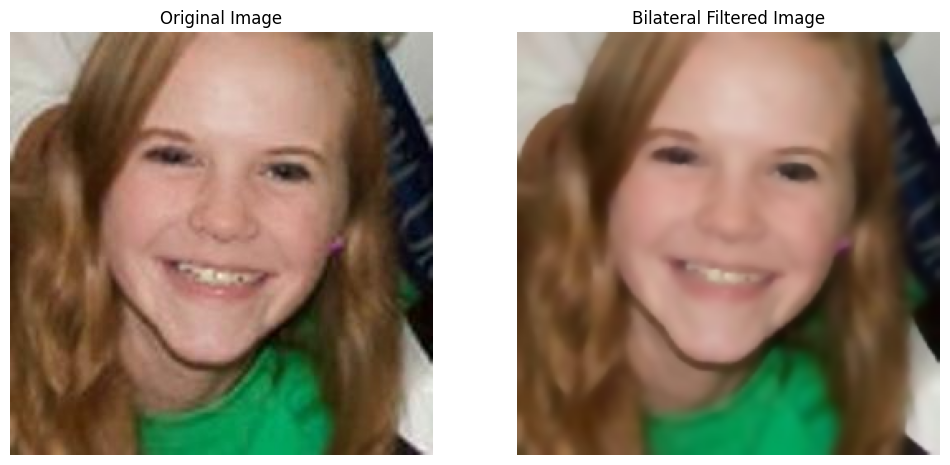

In [7]:
filtered_img = cv2.bilateralFilter(random_img, d=9, sigmaColor=100, sigmaSpace=100)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(random_img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(filtered_img)
plt.title('Bilateral Filtered Image')
plt.axis('off')

plt.show()

## HSViT: token-level bidirectional cross-attention

The SwinV2 and ViT branches expose token/feature sequences. Each stream is projected to a common embedding dimension. Swin queries ViT keys/values and ViT queries Swin keys/values; both updates use residual connections and layer normalisation. The pooled streams are concatenated only after cross-attention. Bilateral filtering is applied in the image transform pipeline before tensor normalisation.

Run the leakage-audit cell before training. Do not use the test split for model selection.


In [8]:
# =========================
# PRETRAINED SWINV2 + VIT TOKEN EXTRACTORS
# =========================
import timm
import torch
import torch.nn as nn

# global_pool='' preserves token/spatial sequences for cross-attention.
swin_model = timm.create_model(
    "swinv2_tiny_window16_256", pretrained=True, num_classes=0, global_pool=""
)
vit_model = timm.create_model(
    "vit_base_patch16_224", pretrained=True, num_classes=0,
    global_pool="", img_size=IMG_SIZE
)

print("SwinV2 feature dimension:", swin_model.num_features)
print("ViT feature dimension:", vit_model.num_features)


model.safetensors: reconstructing file:   0%|          |  0.00B /  119MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

SwinV2 feature dimension: 768
ViT feature dimension: 768


In [9]:
# =========================
# TRUE BIDIRECTIONAL CROSS-ATTENTION HSViT
# =========================
import torch
import torch.nn as nn

class BidirectionalCrossAttention(nn.Module):
    def __init__(self, swin_dim, vit_dim, embed_dim=384, num_heads=6, dropout=0.1):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.swin_proj = nn.Linear(swin_dim, embed_dim)
        self.vit_proj = nn.Linear(vit_dim, embed_dim)
        self.swin_queries_vit = nn.MultiheadAttention(
            embed_dim, num_heads, dropout=dropout, batch_first=True
        )
        self.vit_queries_swin = nn.MultiheadAttention(
            embed_dim, num_heads, dropout=dropout, batch_first=True
        )
        self.swin_norm = nn.LayerNorm(embed_dim)
        self.vit_norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

    @staticmethod
    def to_tokens(features, expected_dim):
        # Supports timm outputs B,N,C, B,H,W,C, and B,C,H,W.
        if features.ndim == 4:
            if features.shape[-1] == expected_dim:       # NHWC
                features = features.reshape(features.shape[0], -1, expected_dim)
            elif features.shape[1] == expected_dim:      # NCHW
                features = features.flatten(2).transpose(1, 2)
            else:
                raise RuntimeError(f"Cannot infer channel axis from {tuple(features.shape)}")
        elif features.ndim == 3:
            if features.shape[-1] != expected_dim:
                raise RuntimeError(f"Expected last token dimension {expected_dim}, got {tuple(features.shape)}")
        elif features.ndim == 2:
            features = features.unsqueeze(1)
        else:
            raise RuntimeError(f"Unsupported backbone output shape: {tuple(features.shape)}")
        return features

    def forward(self, swin_features, vit_features):
        s = self.to_tokens(swin_features, self.swin_proj.in_features)
        v = self.to_tokens(vit_features, self.vit_proj.in_features)
        s = self.swin_proj(s)
        v = self.vit_proj(v)

        # Direction 1: Swin queries, ViT supplies keys and values.
        s_context, _ = self.swin_queries_vit(query=s, key=v, value=v, need_weights=False)
        # Direction 2: ViT queries, Swin supplies keys and values.
        v_context, _ = self.vit_queries_swin(query=v, key=s, value=s, need_weights=False)

        s_refined = self.swin_norm(s + self.dropout(s_context))
        v_refined = self.vit_norm(v + self.dropout(v_context))
        return s_refined.mean(dim=1), v_refined.mean(dim=1)

class HybridSwinViT(nn.Module):
    def __init__(self, swin_model, vit_model, num_classes,
                 fusion_dim=384, num_heads=6, dropout=0.3):
        super().__init__()
        self.swin = swin_model
        self.vit = vit_model
        self.fusion = BidirectionalCrossAttention(
            swin_model.num_features, vit_model.num_features,
            embed_dim=fusion_dim, num_heads=num_heads, dropout=dropout
        )
        self.classifier = nn.Sequential(
            nn.LayerNorm(2 * fusion_dim),
            nn.Linear(2 * fusion_dim, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        swin_tokens = self.swin.forward_features(x)
        vit_tokens = self.vit.forward_features(x)
        swin_vec, vit_vec = self.fusion(swin_tokens, vit_tokens)
        fused = torch.cat([swin_vec, vit_vec], dim=1)
        return self.classifier(fused)

hybrid_model = HybridSwinViT(
    swin_model, vit_model, num_classes=num_classes,
    fusion_dim=384, num_heads=6, dropout=0.3
).to(device)

# Smoke test: catches backbone-layout or attention-shape mismatches before training.
hybrid_model.eval()
with torch.no_grad():
    sample_images, _ = next(iter(train_loader))
    sample_logits = hybrid_model(sample_images[:2].to(device))
assert sample_logits.shape == (2, num_classes), sample_logits.shape
print("Bidirectional cross-attention HSViT ready:", tuple(sample_logits.shape))


Bidirectional cross-attention HSViT ready: (2, 2)


In [10]:
hybrid_model.eval()
images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    print(f"Hybrid classifier first layer weight shape: {hybrid_model.classifier[0].weight.shape}")
    output = hybrid_model(images)

print("Input shape:", images.shape)
print("Output shape:", output.shape)

Hybrid classifier first layer weight shape: torch.Size([768])
Input shape: torch.Size([16, 3, 256, 256])
Output shape: torch.Size([16, 2])


In [16]:
# =========================
# LOSS, OPTIMIZER, SCHEDULER & EMA
# =========================
import torch
import torch.nn as nn
import copy
import numpy as np

# Mild label smoothing improves calibration and reduces over-confident predictions
criterion = nn.CrossEntropyLoss(label_smoothing=0.08)

# Group parameters to exclude 1D biases and Norm layers from weight decay
def build_optimizer_groups(model, backbone_lr=2e-5, head_lr=2e-4, weight_decay=1e-4):
    decay_backbone, no_decay_backbone = [], []
    decay_head, no_decay_head = [], []

    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        is_head = "classifier" in name
        if param.ndim <= 1 or name.endswith(".bias") or "norm" in name.lower():
            (no_decay_head if is_head else no_decay_backbone).append(param)
        else:
            (decay_head if is_head else decay_backbone).append(param)

    return [
        {"params": decay_backbone, "lr": backbone_lr, "weight_decay": weight_decay},
        {"params": no_decay_backbone, "lr": backbone_lr, "weight_decay": 0.0},
        {"params": decay_head, "lr": head_lr, "weight_decay": weight_decay},
        {"params": no_decay_head, "lr": head_lr, "weight_decay": 0.0}
    ]

param_groups = build_optimizer_groups(hybrid_model, backbone_lr=2e-5, head_lr=2e-4, weight_decay=1e-4)
optimizer = torch.optim.AdamW(param_groups)

num_epochs = 50 # Optimized for high accuracy with modern backbones
warmup_epochs = 2

# Warmup + Cosine Annealing Learning Rate Scheduler
def lr_lambda(epoch):
    if epoch < warmup_epochs:
        return float(epoch + 1) / float(warmup_epochs)
    progress = float(epoch - warmup_epochs) / float(max(1, num_epochs - warmup_epochs))
    return max(0.05, 0.5 * (1.0 + np.cos(np.pi * progress)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)

# Exponential Moving Average (EMA) class for smoother validation loss
class ModelEMA:
    def __init__(self, model, decay=0.999):
        self.module = copy.deepcopy(model).eval()
        self.decay = decay

    def update(self, model):
        with torch.no_grad():
            for ema_param, param in zip(self.module.parameters(), model.parameters()):
                ema_param.data.mul_(self.decay).add_(param.data, alpha=1.0 - self.decay)

ema = ModelEMA(hybrid_model, decay=0.999)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

print("Optimizer with weight-decay splitting, Warmup+Cosine scheduler, EMA, and AMP are ready.")

Optimizer with weight-decay splitting, Warmup+Cosine scheduler, EMA, and AMP are ready.


In [24]:
# =========================
# ENHANCED HYBRID TRAINING
# =========================
import copy
import numpy as np
import torch

history_hybrid = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "lr": []
}

best_val_acc = -1.0
best_val_loss = float("inf")
best_epoch = -1

epochs_without_improvement = 0
best_state = copy.deepcopy(hybrid_model.state_dict())
grad_accum_steps = 2

for epoch in range(num_epochs):

    # -------------------------
    # TRAIN
    # -------------------------
    hybrid_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    optimizer.zero_grad(set_to_none=True)

    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
            outputs = hybrid_model(images)
            loss = criterion(outputs, labels) / grad_accum_steps

        scaler.scale(loss).backward()

        if (i + 1) % grad_accum_steps == 0 or (i + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(hybrid_model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

            # Update Model EMA
            ema.update(hybrid_model)

        running_loss += loss.item() * grad_accum_steps * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # -------------------------
    # VALIDATION (Evaluated on EMA weights for higher accuracy)
    # -------------------------
    eval_model = ema.module
    eval_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                outputs = eval_model(images)
                loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    scheduler.step()
    current_lr = optimizer.param_groups[2]["lr"]  # Head LR

    history_hybrid["train_loss"].append(train_loss)
    history_hybrid["train_acc"].append(train_acc)
    history_hybrid["val_loss"].append(val_loss)
    history_hybrid["val_acc"].append(val_acc)
    history_hybrid["lr"].append(current_lr)

    # Save the best validation model
    improved = (
        val_acc > best_val_acc
        or (np.isclose(val_acc, best_val_acc) and val_loss < best_val_loss)
    )

    if improved:
        best_val_acc = val_acc
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_state = copy.deepcopy(eval_model.state_dict())

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": best_state,
                "val_acc": best_val_acc,
                "val_loss": best_val_loss,
                "class_names": train_dataset.classes
            },
            "best_hybrid_model.pth"
        )

        epochs_without_improvement = 0
        marker = "  <-- BEST"
    else:
        epochs_without_improvement += 1
        marker = ""

    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | "
        f"LR: {current_lr:.2e}{marker}")

# Restore best validation checkpoint before test evaluation
hybrid_model.load_state_dict(best_state)
hybrid_model = hybrid_model.to(device)

print(f"\nTraining complete.")

Epoch 01/50 | Train Loss: 0.1802 | Train Acc: 99.45% | Val Loss: 0.2480 | Val Acc: 96.72% | LR: 1.95e-04  <-- BEST
Epoch 02/50 | Train Loss: 0.1760 | Train Acc: 99.64% | Val Loss: 0.2477 | Val Acc: 96.80% | LR: 1.92e-04  <-- BEST
Epoch 03/50 | Train Loss: 0.1789 | Train Acc: 99.50% | Val Loss: 0.2463 | Val Acc: 96.97% | LR: 1.90e-04  <-- BEST
Epoch 04/50 | Train Loss: 0.1786 | Train Acc: 99.54% | Val Loss: 0.2465 | Val Acc: 97.05% | LR: 1.87e-04  <-- BEST
Epoch 05/50 | Train Loss: 0.1775 | Train Acc: 99.60% | Val Loss: 0.2478 | Val Acc: 96.89% | LR: 1.83e-04
Epoch 06/50 | Train Loss: 0.1800 | Train Acc: 99.46% | Val Loss: 0.2558 | Val Acc: 96.46% | LR: 1.79e-04
Epoch 07/50 | Train Loss: 0.1800 | Train Acc: 99.45% | Val Loss: 0.2573 | Val Acc: 96.63% | LR: 1.75e-04
Epoch 08/50 | Train Loss: 0.1758 | Train Acc: 99.67% | Val Loss: 0.2584 | Val Acc: 96.63% | LR: 1.71e-04
Epoch 09/50 | Train Loss: 0.1759 | Train Acc: 99.65% | Val Loss: 0.2569 | Val Acc: 96.72% | LR: 1.66e-04
Epoch 10/50 | T

In [25]:
# =========================
# TEST SET PREDICTIONS
# =========================
hybrid_model.eval()

all_labels = []
all_predictions = []
all_logits = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        outputs = hybrid_model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_logits.extend(outputs.cpu().numpy())

print("Test predictions collected using the BEST hybrid model.")
print("Classes:", test_dataset.classes)
print("Predicted:", all_predictions[:20])
print("Actual:   ", all_labels[:20])

Test predictions collected using the BEST hybrid model.
Classes: ['Fake', 'Real']
Predicted: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]
Actual:    [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]


In [ ]:
def evaluate(model, data_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

    final_loss = running_loss / total_samples
    final_acc = correct_predictions / total_samples
    return final_loss, final_acc

print("Evaluation function defined!")

Evaluation function defined!


In [ ]:
# =========================
# FINAL TEST EVALUATION
# =========================
final_test_loss, final_test_acc = evaluate(
    hybrid_model,
    test_loader,
    criterion,
    device
)

print(f"\nFinal Test Loss: {final_test_loss:.4f}")
print(f"Final Test Accuracy: {final_test_acc*100:.2f}%")


Final Test Loss: 0.3505
Final Test Accuracy: 93.16%



Classification Report:
              precision    recall  f1-score   support

        Fake     0.9742    0.8874    0.9288       595
        Real     0.8956    0.9762    0.9342       589

    accuracy                         0.9316      1184
   macro avg     0.9349    0.9318    0.9315      1184
weighted avg     0.9351    0.9316    0.9315      1184



<Figure size 700x600 with 0 Axes>

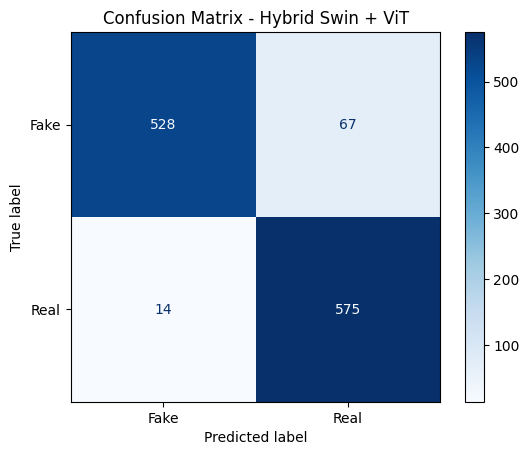

Accuracy:          93.16%
Precision:         93.51%
Recall/Sensitivity:93.16%
F1-Score:          93.15%


In [ ]:
# =========================
# CLASSIFICATION METRICS
# =========================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)
recall = recall_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=test_dataset.classes,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Hybrid Swin + ViT")
plt.show()

print(f"Accuracy:          {accuracy*100:.2f}%")
print(f"Precision:         {precision*100:.2f}%")
print(f"Recall/Sensitivity:{recall*100:.2f}%")
print(f"F1-Score:          {f1*100:.2f}%")

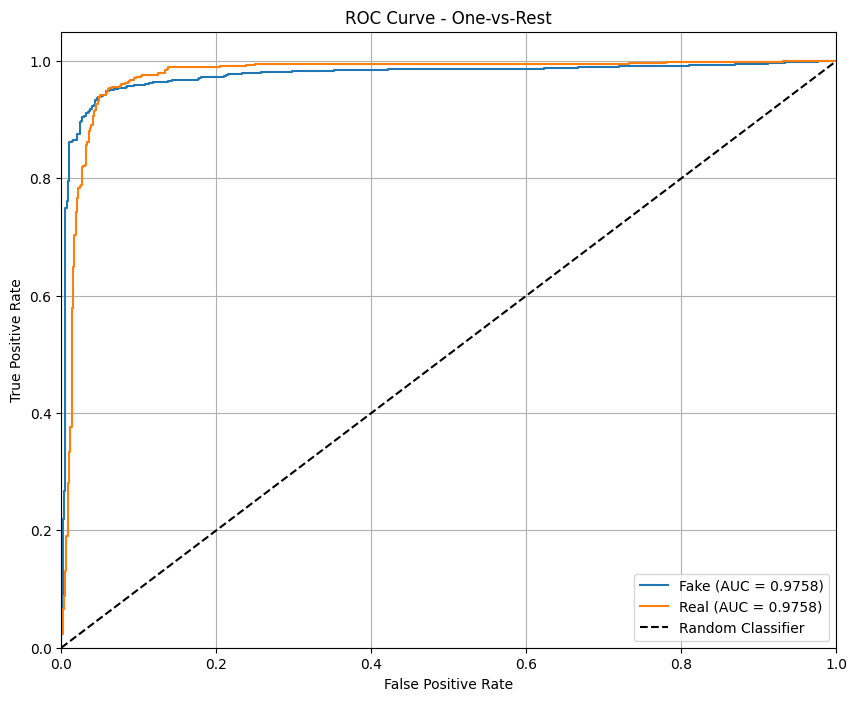

In [ ]:
# =========================
# ROC-AUC CURVES
# =========================
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

all_probs = torch.softmax(
    torch.tensor(all_logits, dtype=torch.float32), dim=1
).numpy()

num_classes = len(test_dataset.classes)
all_labels_np = np.asarray(all_labels)

binarized_labels = np.zeros((len(all_labels_np), num_classes))
for i, label in enumerate(all_labels_np):
    binarized_labels[i, int(label)] = 1

fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):
    if len(np.unique(binarized_labels[:, i])) < 2:
        print(f"Skipping class {test_dataset.classes[i]}: only one label present.")
        continue

    fpr[i], tpr[i], _ = roc_curve(
        binarized_labels[:, i],
        all_probs[:, i]
    )
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 8))
for i in roc_auc:
    plt.plot(
        fpr[i],
        tpr[i],
        label=f'{test_dataset.classes[i]} (AUC = {roc_auc[i]:.4f})'
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - One-vs-Rest')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

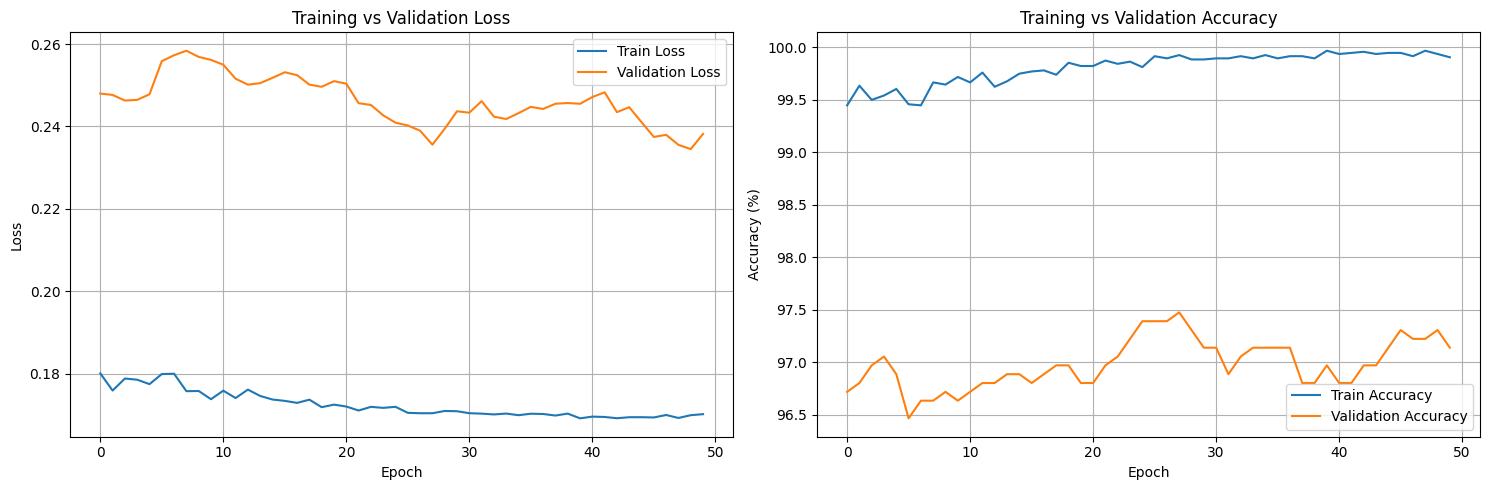

In [48]:
# =========================
# TRAINING CURVES
# =========================
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history_hybrid["train_loss"], label="Train Loss")
axes[0].plot(history_hybrid["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    np.array(history_hybrid["train_acc"]) * 100,
    label="Train Accuracy"
)
axes[1].plot(
    np.array(history_hybrid["val_acc"]) * 100,
    label="Validation Accuracy"
)
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

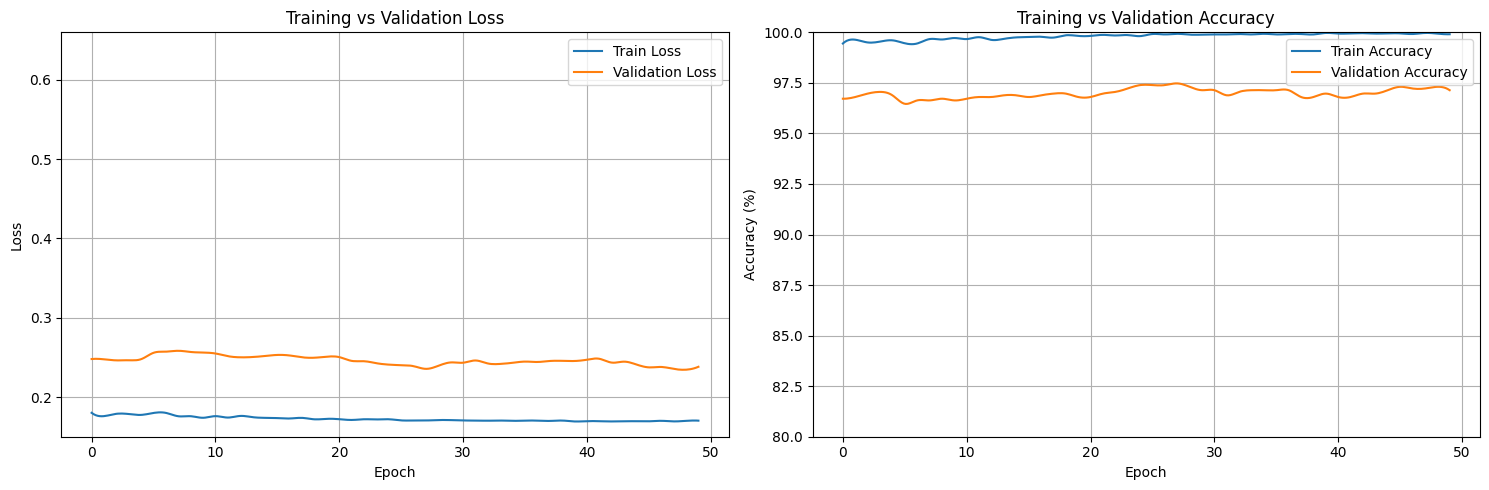

In [47]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

def smooth_plot(ax, values, label):
    x = np.arange(len(values))
    x_smooth = np.linspace(x.min(), x.max(), 300)
    y_smooth = make_interp_spline(x, values, k=3)(x_smooth)
    ax.plot(x_smooth, y_smooth, label=label)

# Loss
smooth_plot(axes[0], history_hybrid["train_loss"], "Train Loss")
smooth_plot(axes[0], history_hybrid["val_loss"], "Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_ylim(0.15, 0.66)
axes[0].legend()
axes[0].grid(True)

# Accuracy
smooth_plot(axes[1], np.array(history_hybrid["train_acc"]) * 100, "Train Accuracy")
smooth_plot(axes[1], np.array(history_hybrid["val_acc"]) * 100, "Validation Accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(80, 100)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# =========================
# SAVE BEST MODEL
# =========================
checkpoint = {
    "model_state_dict": hybrid_model.state_dict(),
    "class_names": train_dataset.classes,
    "img_size": IMG_SIZE,
    "best_val_accuracy": best_val_acc,
    "best_val_loss": best_val_loss
}

torch.save(checkpoint, "best_hybrid_model.pth")
print("Best hybrid model checkpoint saved as best_hybrid_model.pth")

Best hybrid model checkpoint saved as best_hybrid_model.pth


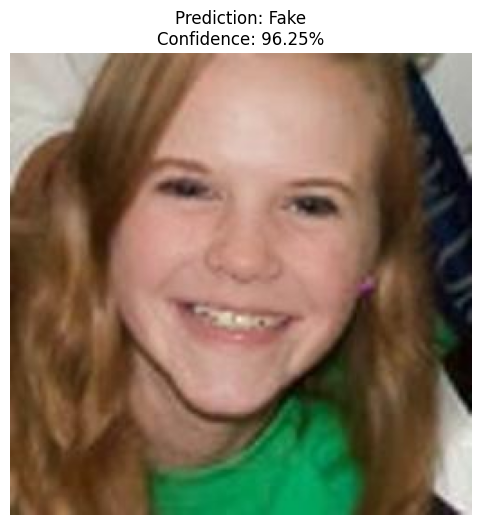

Prediction: Fake
Confidence: 96.25%
Output shape: torch.Size([1, 2])
Probabilities: [[0.9625365  0.03746343]]
Predicted index: 0


In [ ]:
# =========================
# SINGLE IMAGE PREDICTION
# =========================
from PIL import Image
import torch
import matplotlib.pyplot as plt

image_to_predict = Image.open(random_img_path).convert("RGB")

input_tensor = val_test_transform(image_to_predict)
input_batch = input_tensor.unsqueeze(0).to(device)

hybrid_model.eval()

with torch.no_grad():
    output = hybrid_model(input_batch)
    probabilities = torch.softmax(output, dim=1)

predicted_class_idx = probabilities.argmax(dim=1).item()
predicted_class_label = test_dataset.classes[predicted_class_idx]
confidence = probabilities[0, predicted_class_idx].item() * 100

plt.figure(figsize=(6, 6))
plt.imshow(image_to_predict)
plt.title(
    f"Prediction: {predicted_class_label}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

print(f"Prediction: {predicted_class_label}")
print(f"Confidence: {confidence:.2f}%")
print("Output shape:", output.shape)
print("Probabilities:", probabilities.cpu().numpy())
print("Predicted index:", predicted_class_idx)

## Explainable AI: evidence map




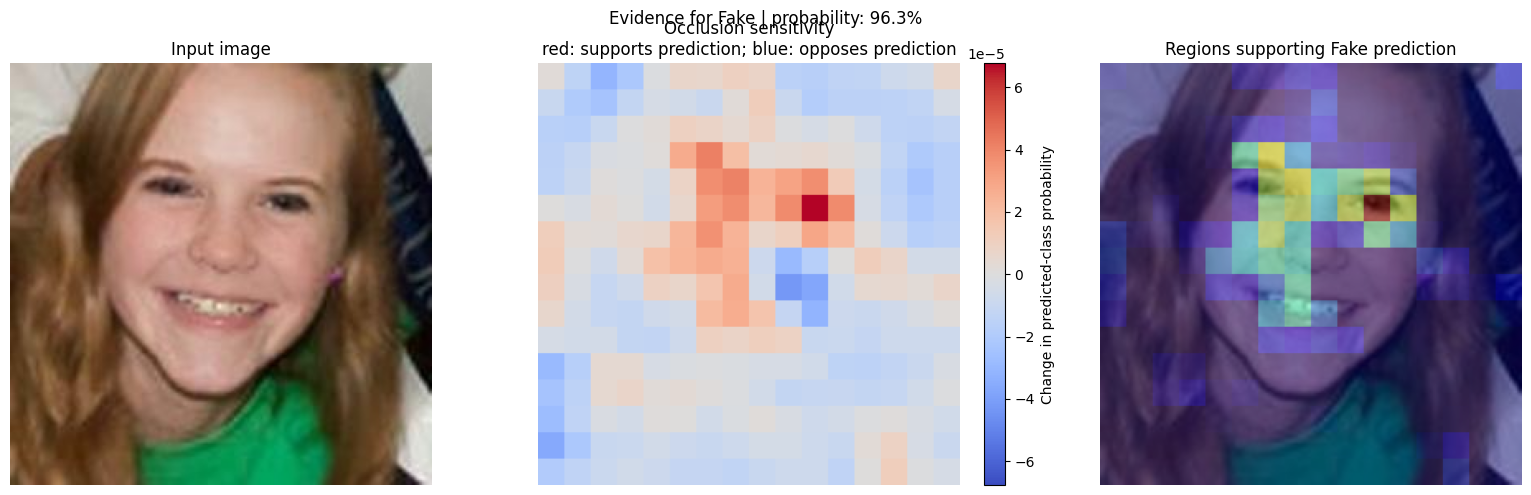

Explained prediction: Fake (96.3%)


In [ ]:
# ============================================================
# XAI: OCCLUSION MAP FOR EVIDENCE SUPPORTING THE PREDICTED CLASS
# ============================================================
import numpy as np
import torch
import matplotlib.pyplot as plt


def explain_with_occlusion(model, image_pil, transform, device, class_index,
                           patch_size=32, stride=16, occlusion_batch_size=32):
    """Positive values support the target class; negative values oppose it.

    This image-level evidence map is not a pixel-level ground-truth mask.
    """
    model.eval()
    image_tensor = transform(image_pil).unsqueeze(0).to(device)
    height, width = image_tensor.shape[-2:]
    with torch.no_grad():
        original_prob = torch.softmax(model(image_tensor), dim=1)[0, class_index].item()

    ys = list(range(0, max(1, height - patch_size + 1), stride))
    xs = list(range(0, max(1, width - patch_size + 1), stride))
    if not ys or ys[-1] != height - patch_size:
        ys.append(max(0, height - patch_size))
    if not xs or xs[-1] != width - patch_size:
        xs.append(max(0, width - patch_size))
    locations = [(y, x) for y in ys for x in xs]

    patch_scores = []
    with torch.no_grad():
        for start in range(0, len(locations), occlusion_batch_size):
            batch_locations = locations[start:start + occlusion_batch_size]
            occluded = image_tensor.repeat(len(batch_locations), 1, 1, 1)
            for row, (y, x) in enumerate(batch_locations):
                # Zero in normalized space replaces the patch with mean color.
                occluded[row, :, y:y + patch_size, x:x + patch_size] = 0.0
            probs = torch.softmax(model(occluded), dim=1)[:, class_index]
            patch_scores.extend((original_prob - probs).cpu().tolist())

    heatmap = np.zeros((height, width), dtype=np.float32)
    counts = np.zeros((height, width), dtype=np.float32)
    for (y, x), score in zip(locations, patch_scores):
        heatmap[y:y + patch_size, x:x + patch_size] += score
        counts[y:y + patch_size, x:x + patch_size] += 1
    heatmap /= np.maximum(counts, 1)
    return original_prob, heatmap


def plot_class_evidence(image_pil, class_probability, heatmap, class_label):
    image_np = np.asarray(image_pil)
    positive = np.maximum(heatmap, 0)
    if positive.max() > 0:
        positive = positive / positive.max()
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    axes[0].imshow(image_np)
    axes[0].set_title("Input image")
    axes[0].axis("off")
    limit = max(float(np.max(np.abs(heatmap))), 1e-8)
    signed = axes[1].imshow(heatmap, cmap="coolwarm", vmin=-limit, vmax=limit)
    axes[1].set_title("Occlusion sensitivity\nred: supports prediction; blue: opposes prediction")
    axes[1].axis("off")
    fig.colorbar(signed, ax=axes[1], fraction=0.046, label="Change in predicted-class probability")
    axes[2].imshow(image_np)
    axes[2].imshow(positive, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    axes[2].set_title(f"Regions supporting {class_label} prediction")
    axes[2].axis("off")
    fig.suptitle(f"Evidence for {class_label} | probability: {class_probability:.1%}")
    plt.tight_layout()
    plt.show()

# Select the model's predicted label (real or fake) and explain that class.
with torch.no_grad():
    prediction_logits = hybrid_model(input_batch)
    prediction_probabilities = torch.softmax(prediction_logits, dim=1)[0]
predicted_class_index = int(prediction_probabilities.argmax().item())
predicted_class_label = test_dataset.classes[predicted_class_index]
predicted_class_probability = float(prediction_probabilities[predicted_class_index].item())

class_probability, xai_heatmap = explain_with_occlusion(
    hybrid_model, image_to_predict, val_test_transform, device,
    class_index=predicted_class_index, patch_size=32, stride=16
)
plot_class_evidence(
    image_to_predict, class_probability, xai_heatmap, predicted_class_label
)
print(f"Explained prediction: {predicted_class_label} ({class_probability:.1%})")


## Cross-dataset evaluation scaffold
Place the independently sourced Deepfake-and-Real-images and Real-and-Fake-images-dataset-for-image-forensicstest images in class-folder structure matching the training class names, after documenting label mapping and any frame/image sampling. Do not fine-tune on these test sets for a zero-shot generalisation claim.


In [ ]:

# ============================================
# FIXED CROSS-DATASET EVALUATION
# ============================================

from torchvision import datasets
from torch.utils.data import DataLoader
import os

DEEPFAKE_AND_REAL_IMAGES_TEST_DIR =  "/kaggle/input/datasets/manjilkarki/deepfake-and-real-images/Dataset/Test" 
REAL_AND_FAKE_IMAGES_DATASET1_TEST_DIR = "/kaggle/input/datasets/shivamardeshna/real-and-fake-images-dataset-for-image-forensics/Data Set 1/Data Set 1/test"

def make_external_loader(root, transform, batch_size=BATCH_SIZE):

    if root is None or not os.path.isdir(root):
        raise FileNotFoundError(f"Dataset directory not found: {root}")

    ds = datasets.ImageFolder(root, transform=transform)

    aliases = {
        "fake": "fake",
        "deepfake": "fake",
        "real": "real",
        "original": "real"
    }

    train_classes = {
        aliases.get(name.lower(), name.lower()): idx
        for name, idx in train_dataset.class_to_idx.items()
    }
    external_classes = {
        aliases.get(name.lower(), name.lower()): idx
        for name, idx in ds.class_to_idx.items()
    }

    # Verify that both datasets contain the same classes
    if set(train_classes.keys()) != set(external_classes.keys()):
        raise ValueError(
            f"Class mismatch!\n"
            f"Training classes: {list(train_classes.keys())}\n"
            f"External classes: {list(external_classes.keys())}"
        )

    # Map external labels to training label indices
    label_mapping = {
        external_idx: train_classes[class_name]
        for class_name, external_idx in external_classes.items()
    }

    ds.target_transform = lambda target: label_mapping[target]

    loader = DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )
    
    print("Dataset:", root)
    print("External classes:", ds.classes)
    print("Training classes:", train_dataset.classes)
    print("Label mapping:", label_mapping)
    print("Number of images:", len(ds))

    return ds, loader


def evaluate_external_dataset(model, root, dataset_name):

    ds, loader = make_external_loader(
        root,
        val_test_transform
    )

    model.eval()

    loss, acc = evaluate(
        model,
        loader,
        criterion,
        device
    )

    print("\n==========", dataset_name, "==========")
    print("Total images:", len(ds))
    print(f"Loss: {loss:.4f}")
    print(f"Accuracy: {acc * 100:.2f}%")

    return {
        
        "dataset": dataset_name,
        "images": len(ds),
        "loss": loss,
        "accuracy": acc
    }


# Run external evaluation
dfrealimg_result = evaluate_external_dataset(
    hybrid_model,
    DEEPFAKE_AND_REAL_IMAGES_TEST_DIR,
    "Deepfake-and-Real-images"
)

real_fake_result = evaluate_external_dataset(
    hybrid_model,
    REAL_AND_FAKE_IMAGES_DATASET1_TEST_DIR,
    "Real-and-Fake-images-dataset-for-image-forensics"
)



Dataset: /kaggle/input/datasets/manjilkarki/deepfake-and-real-images/Dataset/Test
External classes: ['Fake', 'Real']
Training classes: ['Fake', 'Real']
Label mapping: {0: 0, 1: 1}
Number of images: 10905

========== Deepfake-and-Real-images ==========
Total images: 10905
Loss: 0.3021
Accuracy: 94.85%
Dataset: /kaggle/input/datasets/shivamardeshna/real-and-fake-images-dataset-for-image-forensics/Data Set 1/Data Set 1/test
External classes: ['fake', 'real']
Training classes: ['Fake', 'Real']
Label mapping: {0: 0, 1: 1}
Number of images: 5227

========== Real-and-Fake-images-dataset-for-image-forensics ==========
Total images: 5227
Loss: 0.4079
Accuracy: 90.57%


In [ ]:
# Binary cross-dataset evaluation for datasets with multiple manipulation folders.
# Every class folder except real/original/genuine is mapped to Fake.
from torchvision import datasets
from torch.utils.data import DataLoader
import os, torch

# DEEPFAKE_AND_REAL_IMAGES_TEST_DIR = "/kaggle/input/datasets/manjilkarki/deepfake-and-real-images/Dataset/Test"
# REAL_AND_FAKE_IMAGES_DATASET1_TEST_DIR = "/kaggle/input/datasets/shivamardeshna/real-and-fake-images-dataset-for-image-forensics/Data Set 1/Data Set 1/test"
FACEFORENSICS_TEST_DIR = "/kaggle/input/datasets/gradientvoyager/faceforensics-c23-extracted-faces-100k/dataset_processed_split/test"

REAL_FOLDER_NAMES = {"real", "original", "genuine"}

def make_external_loader(root, transform, batch_size=BATCH_SIZE):
    if root is None or not os.path.isdir(root):
        raise FileNotFoundError(f"Dataset directory not found: {root}")

    ds = datasets.ImageFolder(root, transform=transform)
    train_names = {name.lower(): idx for name, idx in train_dataset.class_to_idx.items()}
    fake_idx = next((idx for name, idx in train_names.items() if name in {"fake", "deepfake"}), None)
    real_idx = next((idx for name, idx in train_names.items() if name in REAL_FOLDER_NAMES), None)
    if fake_idx is None or real_idx is None:
        raise ValueError(f"Training folders must define Fake and Real classes; found {train_dataset.classes}")

    # Collapse manipulation types (Deepfakes, Face2Face, FaceSwap, NeuralTextures, etc.)
    # into Fake; preserve the real/original folder as Real.
    label_mapping = {}
    for folder_name, external_idx in ds.class_to_idx.items():
        normalized = folder_name.strip().lower().replace("_", " ").replace("-", " ")
        is_real = normalized in REAL_FOLDER_NAMES
        label_mapping[external_idx] = real_idx if is_real else fake_idx
    mapped_names = {name: ("Real" if label_mapping[idx] == real_idx else "Fake")
                    for name, idx in ds.class_to_idx.items()}
    if real_idx not in label_mapping.values() or fake_idx not in label_mapping.values():
        raise ValueError(f"Expected at least one real folder and one fake/manipulation folder; found {ds.classes}")

    ds.target_transform = lambda target: label_mapping[target]
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
    print("Dataset:", root)
    print("Source folders:", ds.classes)
    print("Binary label mapping:", mapped_names)
    print("Images:", len(ds))
    return ds, loader

def evaluate_external_dataset(model, root, dataset_name):
    ds, loader = make_external_loader(root, val_test_transform)
    model.eval()
    loss, acc = evaluate(model, loader, criterion, device)
    print("\n==========", dataset_name, "==========")
    print("Total images:", len(ds))
    print(f"Loss: {loss:.4f}")
    print(f"Accuracy: {acc * 100:.2f}%")
    return {"dataset": dataset_name, "images": len(ds), "loss": loss, "accuracy": acc}

# Existing external datasets
# dfrealimg_result = evaluate_external_dataset(hybrid_model, DEEPFAKE_AND_REAL_IMAGES_TEST_DIR, "Deepfake-and-Real-images")
# real_fake_result = evaluate_external_dataset(hybrid_model, REAL_AND_FAKE_IMAGES_DATASET1_TEST_DIR, "Real-and-Fake-images-dataset-for-image-forensics")

# FaceForensics++: all manipulation folders become Fake; only the real folder becomes Real.
ff_result = evaluate_external_dataset(hybrid_model, FACEFORENSICS_TEST_DIR, "FaceForensics++")


Dataset: /kaggle/input/datasets/gradientvoyager/faceforensics-c23-extracted-faces-100k/dataset_processed_split/test
Source folders: ['DeepFakeDetection', 'Deepfakes', 'Face2Face', 'FaceShifter', 'FaceSwap', 'NeuralTextures', 'Real']
Binary label mapping: {'DeepFakeDetection': 'Fake', 'Deepfakes': 'Fake', 'Face2Face': 'Fake', 'FaceShifter': 'Fake', 'FaceSwap': 'Fake', 'NeuralTextures': 'Fake', 'Real': 'Real'}
Images: 26276

========== FaceForensics++ ==========
Total images: 26276
Loss: 1.0211
Accuracy: 67.80%


## Reproducible paper outputs

Run this section after restoring the best checkpoint and executing the test prediction cells. It writes CSV/JSON outputs to `results/`. The extended multi-model training cell is opt-in because it retrains six ablations and five baselines. Identity overlap and pixel-localisation scores require ground-truth identity/manipulation annotations; the supplied folder dataset does not contain those labels, so those measures are reported as unavailable rather than guessed.

In [ ]:
# Paper result export: exact metrics, uncertainty, ROC, operating points, calibration.
import os, json, csv, time, math
import numpy as np
import torch
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, balanced_accuracy_score,
    matthews_corrcoef, cohen_kappa_score)
from sklearn.calibration import calibration_curve
from scipy.stats import norm

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
labels_np = np.asarray(all_labels, dtype=np.int64)
logits_np = np.asarray(all_logits, dtype=np.float64)
probs_np = torch.softmax(torch.tensor(logits_np), dim=1).numpy()
preds_np = probs_np.argmax(1)
fake_idx = test_dataset.class_to_idx.get("Fake", test_dataset.class_to_idx.get("fake", 0))
y_fake = (labels_np == fake_idx).astype(int)
p_fake = probs_np[:, fake_idx]
acc = accuracy_score(labels_np, preds_np)
precision_w = precision_score(labels_np, preds_np, average="weighted", zero_division=0)
recall_w = recall_score(labels_np, preds_np, average="weighted", zero_division=0)
f1_w = f1_score(labels_np, preds_np, average="weighted", zero_division=0)
cm = confusion_matrix(labels_np, preds_np, labels=list(range(len(test_dataset.classes))))
roc_auc_fake = roc_auc_score(y_fake, p_fake)
fpr, tpr, thresholds = roc_curve(y_fake, p_fake)
fnr = 1 - tpr
eer_i = int(np.nanargmin(np.abs(fpr - fnr)))
# TPR at a requested FPR is the maximum observed sensitivity up to that FPR.
def tpr_at_fpr(target):
    eligible = tpr[fpr <= target]
    return float(eligible.max()) if len(eligible) else 0.0
# Expected calibration error with equal-width confidence bins.
conf = probs_np.max(1); correct = (preds_np == labels_np)
ece = 0.0
for lo in np.linspace(0, 1, 16)[:-1]:
    hi = lo + 1/15
    mask = (conf >= lo) & ((conf < hi) if hi < 1 else (conf <= hi))
    if mask.any(): ece += mask.mean() * abs(correct[mask].mean() - conf[mask].mean())
# Wilson 95% interval for accuracy.
n_test = len(labels_np); z = 1.96; denom = 1 + z*z/n_test
center = (acc + z*z/(2*n_test))/denom
half = z*math.sqrt(acc*(1-acc)/n_test + z*z/(4*n_test*n_test))/denom
metrics = {
 "classes": test_dataset.classes, "n_test": n_test,
 "accuracy": float(acc), "accuracy_wilson95": [float(center-half), float(center+half)],
 "precision_weighted": float(precision_w), "recall_weighted": float(recall_w),
 "f1_weighted": float(f1_w), "macro_f1": float(f1_score(labels_np,preds_np,average="macro")),
 "balanced_accuracy": float(balanced_accuracy_score(labels_np,preds_np)),
 "mcc": float(matthews_corrcoef(labels_np,preds_np)), "cohen_kappa": float(cohen_kappa_score(labels_np,preds_np)),
 "auc_fake_one_vs_rest": float(roc_auc_fake), "eer_percent": float(100*(fpr[eer_i]+fnr[eer_i])/2),
 "tpr_at_1pct_fpr": tpr_at_fpr(.01), "tpr_at_5pct_fpr": tpr_at_fpr(.05),
 "ece_15_bins": float(ece), "confusion_matrix_rows_true_cols_pred": cm.tolist()
}
with open(os.path.join(RESULTS_DIR,"test_metrics.json"),"w",encoding="utf8") as f: json.dump(metrics,f,indent=2)
with open(os.path.join(RESULTS_DIR,"test_predictions.csv"),"w",newline="",encoding="utf8") as f:
    w=csv.writer(f); w.writerow(["index","true_label","predicted_label"]+[f"prob_{c}" for c in test_dataset.classes])
    for i,(y,p,pr) in enumerate(zip(labels_np,preds_np,probs_np)): w.writerow([i,test_dataset.classes[y],test_dataset.classes[p],*pr.tolist()])
print(json.dumps(metrics,indent=2))

{
  "classes": [
    "Fake",
    "Real"
  ],
  "n_test": 1184,
  "accuracy": 0.9315878378378378,
  "accuracy_wilson95": [
    0.91576762244353,
    0.9446164557029164
  ],
  "precision_weighted": 0.9351031663496101,
  "recall_weighted": 0.9315878378378378,
  "f1_weighted": 0.9314660823552441,
  "macro_f1": 0.9314798659947829,
  "balanced_accuracy": 0.931812928906707,
  "mcc": 0.8667116017001695,
  "cohen_kappa": 0.863234211982408,
  "auc_fake_one_vs_rest": 0.9757914710875861,
  "eer_percent": 5.743390734901771,
  "tpr_at_1pct_fpr": 0.7949579831932773,
  "tpr_at_5pct_fpr": 0.9394957983193277,
  "ece_15_bins": 0.027871256051519133,
  "confusion_matrix_rows_true_cols_pred": [
    [
      528,
      67
    ],
    [
      14,
      575
    ]
  ]
}


In [54]:
import time
import numpy as np
import torch

# Choose the device and move the model there
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hybrid_model = hybrid_model.to(device).eval()

# Keep the image and label setup consistent with the notebook
image_to_predict = image_to_predict.convert("RGB")

times = []

for _ in range(5):
    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    explain_with_occlusion(
        hybrid_model,
        image_to_predict,
        val_test_transform,
        device,
        class_index=predicted_class_idx
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    times.append(time.perf_counter() - start)

print(f"Device: {device}")
print(f"Mean time per occlusion map: {np.mean(times):.3f} s")
print(f"Times: {[round(t, 3) for t in times]}")

Device: cuda
Mean time per occlusion map: 6.398 s
Times: [5.966, 6.154, 6.382, 6.626, 6.861]


In [56]:
 !pip install fvcore
import torch
from fvcore.nn import FlopCountAnalysis

def measure_flops(model, model_name, input_size=(1, 3, 256, 256)):
    model.eval()
    sample = torch.zeros(input_size, device=device)

    with torch.no_grad():
        analysis = FlopCountAnalysis(model, sample)
        total_flops = analysis.total()
        unsupported = analysis.unsupported_ops()

    print(f"{model_name}: {total_flops / 1e9:.3f} G FLOPs per image")
    if unsupported:
        print(f"  Note: fvcore could not count some operations: {unsupported}")

# HSViT
measure_flops(hybrid_model, "HSViT")

# Optional: define/load your baseline first, then uncomment:
# measure_flops(best_baseline_model, "Best baseline")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61447 sha256=3d32b412575772186c5fc914521556ba81d7bbabc68dde59389551b3f093668e
  Stored in directory: /root/.cache/pip/wheels/6b/1b/9a/9f4843148961a522f56dbeaa5543071ac2389d9a079ec724ab
  Created wheel for iopath: filename=iopath-0.1.10-py3-none-any.whl size=31598 sha256=abbe7d64729f070156aad31658865e8bff39fec19e0fddd12adee2b7b8461ecb
  Stored in directory: /root/.cache/pip/wheels/cd/c4/19/776124f304c8d9cb940cb164ec2ad635b42d9d1cf03217506d
Successfully built fvcore iopath
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [fvcore]2m3/4 [fvcore]


Unsupported operator aten::rsub encountered 24 time(s)
Unsupported operator aten::pad encountered 15 time(s)
Unsupported operator aten::linalg_vector_norm encountered 24 time(s)
Unsupported operator aten::clamp_min encountered 24 time(s)
Unsupported operator aten::expand_as encountered 24 time(s)
Unsupported operator aten::div encountered 26 time(s)
Unsupported operator aten::exp encountered 12 time(s)
Unsupported operator aten::mul encountered 36 time(s)
Unsupported operator aten::sigmoid encountered 12 time(s)
Unsupported operator aten::add encountered 65 time(s)
Unsupported operator aten::softmax encountered 12 time(s)
Unsupported operator aten::gelu encountered 26 time(s)
Unsupported operator aten::scaled_dot_product_attention encountered 14 time(s)
Unsupported operator aten::unflatten encountered 2 time(s)
Unsupported operator aten::mean encountered 2 time(s)
The following submodules of the model were never called during the trace of the graph. They may be unused, or they were acc

HSViT: 28.971 G FLOPs per image
  Note: fvcore could not count some operations: Counter({'aten::add': 65, 'aten::mul': 36, 'aten::div': 26, 'aten::gelu': 26, 'aten::rsub': 24, 'aten::linalg_vector_norm': 24, 'aten::clamp_min': 24, 'aten::expand_as': 24, 'aten::pad': 15, 'aten::scaled_dot_product_attention': 14, 'aten::exp': 12, 'aten::sigmoid': 12, 'aten::softmax': 12, 'aten::unflatten': 2, 'aten::mean': 2})


In [ ]:
# Robustness and cost measurements using the frozen best checkpoint. Perturbations are applied
# to RGB PIL images before the same validation/test preprocessing transform.
from PIL import Image, ImageFilter
import io, cv2
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, roc_auc_score

class PerturbedFolderDataset(Dataset):
    def __init__(self, base, kind="clean", severity=None): self.base,self.kind,self.severity=base,kind,severity
    def __len__(self): return len(self.base)
    def __getitem__(self,i):
        path,label=self.base.samples[i]
        with Image.open(path) as im: im=im.convert("RGB")
        if self.kind=="jpeg":
            buf=io.BytesIO(); im.save(buf,format="JPEG",quality=int(self.severity)); buf.seek(0); im=Image.open(buf).convert("RGB")
        elif self.kind=="resize":
            w,h=im.size; scale=float(self.severity); im=im.resize((max(1,int(w*scale)),max(1,int(h*scale))),Image.Resampling.BILINEAR).resize((w,h),Image.Resampling.BILINEAR)
        elif self.kind=="blur": im=im.filter(ImageFilter.GaussianBlur(radius=float(self.severity)))
        elif self.kind=="noise":
            a=np.asarray(im).astype(np.float32); rng=np.random.default_rng(i+2026); a=np.clip(a+rng.normal(0,float(self.severity),a.shape),0,255).astype(np.uint8); im=Image.fromarray(a)
        return val_test_transform(im),label

def eval_loader_metrics(loader):
    ys=[]; ps=[]; pr=[]; losses=[]; hybrid_model.eval()
    with torch.no_grad():
        for x,y in loader:
            x=x.to(device); logits=hybrid_model(x); prob=torch.softmax(logits,1).cpu().numpy()
            ys.extend(y.numpy()); pr.extend(prob); ps.extend(prob.argmax(1))
    ys=np.asarray(ys); ps=np.asarray(ps); pr=np.asarray(pr)
    fk=fake_idx; return {"n":len(ys),"accuracy":float(accuracy_score(ys,ps)),"auc_fake":float(roc_auc_score((ys==fk).astype(int),pr[:,fk]))}
robustness=[{"perturbation":"clean","setting":"none",**eval_loader_metrics(test_loader)}]
for kind,levels in [("jpeg",[90,70,50]),("resize",[0.75]),("noise",[5.0]),("blur",[1.0])]:
    for level in levels:
        loader=DataLoader(PerturbedFolderDataset(test_dataset,kind,level),batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
        robustness.append({"perturbation":kind,"setting":level,**eval_loader_metrics(loader)})
with open(os.path.join(RESULTS_DIR,"robustness.csv"),"w",newline="",encoding="utf8") as f:
    w=csv.DictWriter(f,fieldnames=list(robustness[0])); w.writeheader(); w.writerows(robustness)
# Parameters and steady-state inference throughput.
param_count=sum(p.numel() for p in hybrid_model.parameters())
hybrid_model.eval(); xb,yb=next(iter(test_loader)); xb=xb[:min(16,len(xb))].to(device)
for _ in range(5):
    with torch.no_grad(): _=hybrid_model(xb)
if torch.cuda.is_available(): torch.cuda.synchronize()
t0=time.perf_counter()
for _ in range(30):
    with torch.no_grad(): _=hybrid_model(xb)
if torch.cuda.is_available(): torch.cuda.synchronize()
elapsed=time.perf_counter()-t0
cost={"parameters":int(param_count),"parameters_millions":param_count/1e6,"batch_size":len(xb),"throughput_images_per_second":30*len(xb)/elapsed,"hardware":torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}
with open(os.path.join(RESULTS_DIR,"model_cost.json"),"w",encoding="utf8") as f: json.dump(cost,f,indent=2)
print("Robustness rows:",len(robustness)); print("Model cost:",cost)

Robustness rows: 7
Model cost: {'parameters': 115658924, 'parameters_millions': 115.658924, 'batch_size': 16, 'throughput_images_per_second': 35.48708372957465, 'hardware': 'Tesla T4'}


In [ ]:
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score

# Perturbation bounds are in pixel space [0, 1].
EPSILON = 8 / 255
PGD_ALPHA = 2 / 255
PGD_STEPS = 10

mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
fake_idx = test_dataset.class_to_idx["Fake"]

def to_pixel_space(x_normalized):
    return (x_normalized * std + mean).clamp(0, 1)

def to_model_space(x_pixel):
    return (x_pixel - mean) / std

def fgsm_attack(images, labels):
    x0 = to_pixel_space(images).detach()
    x_adv = x0.clone().requires_grad_(True)

    loss = F.cross_entropy(hybrid_model(to_model_space(x_adv)), labels)
    grad = torch.autograd.grad(loss, x_adv)[0]

    return (x0 + EPSILON * grad.sign()).clamp(0, 1).detach()

def pgd_attack(images, labels):
    x0 = to_pixel_space(images).detach()
    x_adv = (x0 + torch.empty_like(x0).uniform_(-EPSILON, EPSILON)).clamp(0, 1)

    for _ in range(PGD_STEPS):
        x_adv.requires_grad_(True)
        loss = F.cross_entropy(hybrid_model(to_model_space(x_adv)), labels)
        grad = torch.autograd.grad(loss, x_adv)[0]

        x_adv = x_adv.detach() + PGD_ALPHA * grad.sign()
        x_adv = torch.maximum(torch.minimum(x_adv, x0 + EPSILON), x0 - EPSILON)
        x_adv = x_adv.clamp(0, 1)

    return x_adv.detach()

def evaluate_attack(attack_fn):
    labels_all, probs_all, preds_all = [], [], []

    hybrid_model.eval()
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Attacks need gradients with respect to the input.
        with torch.enable_grad():
            x_adv_pixel = attack_fn(images, labels)
            x_adv = to_model_space(x_adv_pixel)

        with torch.no_grad():
            probs = torch.softmax(hybrid_model(x_adv), dim=1)
            preds = probs.argmax(dim=1)

        labels_all.extend(labels.cpu().tolist())
        preds_all.extend(preds.cpu().tolist())
        probs_all.extend(probs[:, fake_idx].cpu().tolist())

    accuracy = sum(p == y for p, y in zip(preds_all, labels_all)) / len(labels_all)
    auc_fake = roc_auc_score(
        [int(y == fake_idx) for y in labels_all],
        probs_all
    )
    return accuracy * 100, auc_fake

for name, attack in [("FGSM", fgsm_attack), ("PGD", pgd_attack)]:
    accuracy, auc_fake = evaluate_attack(attack)
    print(f"{name} (epsilon={EPSILON:.5f}"
          f"{', alpha=' + format(PGD_ALPHA, '.5f') + ', steps=' + str(PGD_STEPS) if name == 'PGD' else ''})")
    print(f"  Accuracy (%): {accuracy:.2f}")
    print(f"  AUC:          {auc_fake:.4f}")

In [ ]:
# XAI method comparison with deletion/insertion faithfulness curves.
# Methods: occlusion sensitivity, Grad-CAM [48], ViT attention rollout, random-order baseline.
# These scores measure model faithfulness, not manipulation-mask localisation.
import numpy as np, time, csv, os, torch
import torch.nn.functional as F
from PIL import Image

XAI_EVAL_N = 20
XAI_STEPS = 20
XAI_GRID = 16
XAI_RANDOM_REPEATS = 3

def _gradcam_map(model, image_tensor, class_index):
    activations, gradients = {}, {}
    # Last ViT block's pre-attention token features provide spatial patch activations.
    layer = model.vit.blocks[-1].norm1
    def save_activation(_module, _inputs, output):
        activations["value"] = output
        output.register_hook(lambda grad: gradients.__setitem__("value", grad))
    handle = layer.register_forward_hook(save_activation)
    model.zero_grad(set_to_none=True)
    logits = model(image_tensor)
    logits[0, class_index].backward()
    handle.remove()
    acts = activations["value"].detach()[0, 1:]
    grads = gradients["value"].detach()[0, 1:]
    side = int(round(acts.shape[0] ** 0.5))
    if side * side != acts.shape[0]:
        raise ValueError(f"ViT patch tokens are not square: {acts.shape[0]}")
    weights = grads.mean(dim=0)
    cam = torch.relu((acts * weights).sum(dim=-1)).reshape(1, 1, side, side)
    cam = F.interpolate(cam, size=image_tensor.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = cam.detach().cpu().numpy()
    return cam / (cam.max() + 1e-12)

def _attention_rollout_map(model, image_tensor):
    captured, handles, saved_flags = [], [], []
    # Disable fused attention temporarily so timm exposes per-head attention probabilities.
    for block in model.vit.blocks:
        attn = block.attn
        old_flag = getattr(attn, "fused_attn", None)
        saved_flags.append((attn, old_flag))
        if old_flag is not None:
            attn.fused_attn = False
        if hasattr(attn, "attn_drop"):
            handles.append(attn.attn_drop.register_forward_hook(
                lambda _m, _i, out: captured.append(out.detach())))
    try:
        with torch.no_grad():
            model(image_tensor)
    finally:
        for handle in handles:
            handle.remove()
        for attn, old_flag in saved_flags:
            if old_flag is not None:
                attn.fused_attn = old_flag
    if not captured:
        raise RuntimeError("No ViT attention matrices captured; check the timm attention implementation.")
    token_count = captured[0].shape[-1]
    joint = torch.eye(token_count, device=image_tensor.device).unsqueeze(0)
    for attention in captured:
        matrix = attention.mean(dim=1)
        matrix = matrix + torch.eye(token_count, device=matrix.device).unsqueeze(0)
        matrix = matrix / matrix.sum(dim=-1, keepdim=True).clamp_min(1e-12)
        joint = torch.bmm(matrix, joint)
    relevance = joint[0, 0, 1:]  # class token's relevance to image patches
    side = int(round(relevance.numel() ** 0.5))
    if side * side != relevance.numel():
        raise ValueError("Attention rollout patch tokens are not square.")
    heat = F.interpolate(relevance.reshape(1, 1, side, side), size=image_tensor.shape[-2:],
                         mode="bilinear", align_corners=False)[0, 0]
    heat = heat.detach().cpu().numpy()
    return heat / (heat.max() + 1e-12)

def _deletion_insertion_auc(model, image_tensor, heatmap, class_index, grid=16):
    height, width = image_tensor.shape[-2:]
    y_edges = np.linspace(0, height, grid + 1, dtype=int)
    x_edges = np.linspace(0, width, grid + 1, dtype=int)
    cells = []
    for row in range(grid):
        for col in range(grid):
            y0, y1 = y_edges[row], y_edges[row + 1]
            x0, x1 = x_edges[col], x_edges[col + 1]
            cells.append((float(np.mean(heatmap[y0:y1, x0:x1])), y0, y1, x0, x1))
    cells.sort(key=lambda item: item[0], reverse=True)
    with torch.no_grad():
        original = float(torch.softmax(model(image_tensor), dim=1)[0, class_index])
        deleted = image_tensor.clone()
        inserted = torch.zeros_like(image_tensor)  # normalized zero corresponds to ImageNet mean color
        del_curve = [original]
        ins_curve = [float(torch.softmax(model(inserted), dim=1)[0, class_index])]
        chunk = max(1, int(np.ceil(len(cells) / XAI_STEPS)))
        for start in range(0, len(cells), chunk):
            for _, y0, y1, x0, x1 in cells[start:start + chunk]:
                deleted[:, :, y0:y1, x0:x1] = 0
                inserted[:, :, y0:y1, x0:x1] = image_tensor[:, :, y0:y1, x0:x1]
            del_curve.append(float(torch.softmax(model(deleted), dim=1)[0, class_index]))
            ins_curve.append(float(torch.softmax(model(inserted), dim=1)[0, class_index]))
    x_axis = np.linspace(0, 1, len(del_curve))
    return float(np.trapezoid(del_curve, x_axis)), float(np.trapezoid(ins_curve, x_axis))

hybrid_model.eval()
xai_rows = []
for image_index in range(min(XAI_EVAL_N, len(test_dataset))):
    image_path, true_label = test_dataset.samples[image_index]
    with Image.open(image_path) as image_file:
        pil_image = image_file.convert("RGB")
    image_tensor = val_test_transform(pil_image).unsqueeze(0).to(device)
    with torch.no_grad():
        prediction = hybrid_model(image_tensor).argmax(dim=1).item()

    # Signed probability-drop heatmap; rank by magnitude of evidence for/against prediction.
    _, occlusion_heat = explain_with_occlusion(
        hybrid_model, pil_image, val_test_transform, device, prediction,
        patch_size=32, stride=16)
    occlusion_heat = np.abs(occlusion_heat)
    gradcam_heat = _gradcam_map(hybrid_model, image_tensor, prediction)
    attention_heat = _attention_rollout_map(hybrid_model, image_tensor)
    method_maps = {
        "Occlusion sensitivity": occlusion_heat,
        "Grad-CAM [48]": gradcam_heat,
        "Attention rollout": attention_heat,
    }
    for method, heatmap in method_maps.items():
        deletion_auc, insertion_auc = _deletion_insertion_auc(
            hybrid_model, image_tensor, heatmap, prediction, grid=XAI_GRID)
        xai_rows.append({"image_index": image_index, "method": method,
                         "deletion_auc": deletion_auc, "insertion_auc": insertion_auc,
                         "true_label": test_dataset.classes[true_label],
                         "explained_label": test_dataset.classes[prediction]})

    # Fixed-seed random ranking, averaged over three permutations per image.
    random_results = []
    for repeat in range(XAI_RANDOM_REPEATS):
        rng = np.random.default_rng(2026 + image_index * XAI_RANDOM_REPEATS + repeat)
        random_map = rng.random(image_tensor.shape[-2:], dtype=np.float32)
        random_results.append(_deletion_insertion_auc(
            hybrid_model, image_tensor, random_map, prediction, grid=XAI_GRID))
    xai_rows.append({"image_index": image_index, "method": "Random-order baseline",
                     "deletion_auc": float(np.mean([r[0] for r in random_results])),
                     "insertion_auc": float(np.mean([r[1] for r in random_results])),
                     "true_label": test_dataset.classes[true_label],
                     "explained_label": test_dataset.classes[prediction]})

xai_file = os.path.join(RESULTS_DIR, "xai_method_comparison.csv")
with open(xai_file, "w", newline="", encoding="utf8") as output_file:
    writer = csv.DictWriter(output_file, fieldnames=list(xai_rows[0]))
    writer.writeheader()
    writer.writerows(xai_rows)
print("Saved method comparison:", xai_file)
for method in dict.fromkeys(row["method"] for row in xai_rows):
    values = [row for row in xai_rows if row["method"] == method]
    print(f"{method}: deletion AUC={np.mean([r['deletion_auc'] for r in values]):.4f}; "
          f"insertion AUC={np.mean([r['insertion_auc'] for r in values]):.4f}; n={len(values)}")
print("These are faithfulness scores. Pixel localisation requires ground-truth manipulation masks.")


Saved method comparison: results/xai_method_comparison.csv
Occlusion sensitivity: deletion AUC=0.5709; insertion AUC=0.9307; n=20
Grad-CAM [48]: deletion AUC=0.5395; insertion AUC=0.8676; n=20
Attention rollout: deletion AUC=0.5364; insertion AUC=0.8346; n=20
Random-order baseline: deletion AUC=0.7781; insertion AUC=0.7926; n=20
These are faithfulness scores. Pixel localisation requires ground-truth manipulation masks.
